# Sesión 2 · De la cartera al resultado técnico: pandas, NumPy y visualización

**Pregunta de negocio:** *¿Cuánto ganamos (o perdemos) en 2025, en qué canales y en qué segmentos de clientes?*

> 🔑 **Versión con soluciones.**

| Bloque | Contenido | Min |
|---|---|---|
| 1 | Carga, exploración y limpieza; NumPy vectorizado | 25 |
| 2 | Unir tablas (BUSCARV) y calcular la cuenta técnica | 25 |
| 3 | Portafolios y segmentos: ¿dónde se pierde dinero? | 20 |
| 4 | Visualización: matplotlib, seaborn y plotly | 25 |
| ⭐ | Demo: ¿y si fueran 50 millones de filas? | 5 |

**Los datos.** 677.991 pólizas reales de RC de autos (dataset público *freMTPL2*) a las que hemos añadido canal, fechas y prima (simulados). Ver `docs/03_caso_de_uso.md`.

In [1]:
# @title ⚙️ Ejecuta esta celda primero (prepara el entorno) { display-mode: "form" }
import os, sys, subprocess
from pathlib import Path

REPO_URL = "https://github.com/SSerraPe/curso-python-finanzas.git"  # ← el profesor lo cambia por la URL real del repositorio
EN_COLAB = "google.colab" in sys.modules

if EN_COLAB:
    if not Path("/content/curso-python-finanzas").exists():
        subprocess.run(["git", "clone", "-q", "--depth", "1", REPO_URL, "/content/curso-python-finanzas"], check=True)
    os.chdir("/content/curso-python-finanzas")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements-colab.txt"], check=True)
else:
    # En tu ordenador: nos situamos en la carpeta raíz del curso (la que tiene data/ y src/)
    while not (Path("data").is_dir() and Path("src").is_dir()) and Path.cwd() != Path.cwd().parent:
        os.chdir("..")

sys.path.insert(0, str(Path("src").resolve()))
print("✅ Entorno listo. Carpeta de trabajo:", Path.cwd())

✅ Entorno listo. Carpeta de trabajo: /content/curso-python-finanzas


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from curso_seguros.datos import cargar_cartera, cargar_siniestros_referencia, DATA, OUTPUT
from curso_seguros.comprobar import comprobar

pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
pd.set_option("display.max_columns", 30)

---
# Bloque 1 · Carga, exploración y limpieza

### Pregunta diagnóstica (repaso)
Tenemos 2 pólizas. A: prima 100 €, siniestros 300 €. B: prima 900 €, siniestros 450 €. ¿Cuál es la siniestralidad **de la cartera**?

- (a) 175 % → media de 300 % y 50 %
- (b) 75 % → (300 + 450) / (100 + 900)
- (c) 125 %

<details><summary>Respuesta</summary>

**(b)**. Un ratio de grupo es siempre un **cociente de sumas**: Σ costes / Σ primas. Promediar ratios individuales da el mismo peso a una póliza de 100 € que a una de 900 €. Esta regla la usaremos durante todo el curso.
</details>

In [3]:
cartera = cargar_cartera()           # lee data/cartera/cartera_2025.parquet
siniestros = cargar_siniestros_referencia()

print(cartera.shape, siniestros.shape)
cartera.head()

(677991, 14) (26444, 8)


,id_poliza,canal,fecha_efecto,fecha_vencimiento,prima_anual,zona,region,potencia,antig_vehiculo,edad_conductor,bonus_malus,marca,combustible,densidad
0,1,Bancaseguros,2025-07-05,2025-08-10,195.70,D,Rhone-Alpes,5,0,55,50,B12,Regular,1217
1,3,Agentes,2025-01-06,2025-10-14,176.25,D,Rhone-Alpes,5,0,55,50,B12,Regular,1217
2,5,Directo,2025-02-01,2025-11-02,137.50,B,Picardie,6,2,52,50,B12,Diesel,54
3,10,Directo,2025-07-09,2025-08-11,130.85,B,Aquitaine,7,0,46,50,B12,Diesel,76
4,11,Bancaseguros,2025-02-03,2025-12-07,144.87,B,Aquitaine,7,0,46,50,B12,Diesel,76


> **Parquet** es un formato de fichero para tablas: guarda los tipos de dato, ocupa ~5 veces menos que un CSV y se lee mucho más rápido. Lo veremos al final.

### Primer vistazo: `info()` y `describe()`

In [4]:
cartera.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 677991 entries, 0 to 677990
Data columns (total 14 columns):
 #   Column             Non-Null Count   Dtype         
---  ------             --------------   -----         
 0   id_poliza          677991 non-null  int64         
 1   canal              677991 non-null  object        
 2   fecha_efecto       677991 non-null  datetime64[ns]
 3   fecha_vencimiento  677991 non-null  datetime64[ns]
 4   prima_anual        677991 non-null  float64       
 5   zona               677991 non-null  object        
 6   region             677991 non-null  object        
 7   potencia           677991 non-null  int64         
 8   antig_vehiculo     677991 non-null  int64         
 9   edad_conductor     677991 non-null  int64         
 10  bonus_malus        677991 non-null  int64         
 11  marca              677991 non-null  object        
 12  combustible        677991 non-null  object        
 13  densidad           677991 non-null  int64   

In [5]:
cartera.describe().T

,count,mean,min,25%,50%,75%,max,std
id_poliza,"677,991.00","2,621,885.52",1.00,"1,157,964.50","2,272,157.00","4,046,271.00","6,114,330.00","1,641,775.74"
fecha_efecto,677991,2025-03-28 01:37:41.260104704,2025-01-01 00:00:00,2025-01-01 00:00:00,2025-02-26 00:00:00,2025-05-27 00:00:00,2025-12-31 00:00:00,NaN
fecha_vencimiento,677991,2025-10-06 23:28:46.955667712,2025-01-02 00:00:00,2025-08-08 00:00:00,2025-11-06 00:00:00,2026-01-01 00:00:00,2026-01-01 00:00:00,NaN
prima_anual,"677,991.00",248.82,120.00,158.38,196.24,319.22,"1,449.51",137.34
potencia,"677,991.00",6.45,4.00,5.00,6.00,7.00,15.00,2.05
antig_vehiculo,"677,991.00",7.04,0.00,2.00,6.00,11.00,100.00,5.67
edad_conductor,"677,991.00",45.50,18.00,34.00,44.00,55.00,100.00,14.14
bonus_malus,"677,991.00",59.76,50.00,50.00,50.00,64.00,230.00,15.64
densidad,"677,991.00","1,792.41",1.00,92.00,393.00,"1,658.00","27,000.00","3,958.57"


**¿Qué te llama la atención?** Mira el máximo de `antig_vehiculo` (100 años) y de `edad_conductor` (100). En los sistemas reales, 99/100 suele ser un código de "desconocido" o un error de captura.

In [6]:
cartera["antig_vehiculo"].value_counts().sort_index().tail(8)

antig_vehiculo
80      3
81      3
82      1
83      2
84      1
85      1
99     23
100    25
Name: count, dtype: int64

In [7]:
siniestros.describe(percentiles=[0.5, 0.9, 0.99, 0.999])["importe"]

count      26,444.00
mean        2,265.51
min             1.00
50%         1,172.00
90%         2,767.60
99%        16,451.22
99.9%     152,223.24
max     4,075,400.56
std        29,371.03
Name: importe, dtype: float64

Los importes tienen una **cola muy pesada**: la mediana es ~1.170 €, pero el máximo supera los 4 millones. Lo estudiaremos en la sesión 4. De momento basta con saber que **un único siniestro puede mover el resultado de un segmento entero**.

### Chequeos básicos de calidad

In [8]:
print("Pólizas duplicadas:", cartera["id_poliza"].duplicated().sum())
print("Nulos por columna:\n", cartera.isna().sum()[cartera.isna().sum() > 0])
print("Siniestros de pólizas que no están en cartera:",
      (~siniestros["id_poliza"].isin(cartera["id_poliza"])).sum())
print("Canales:", cartera["canal"].unique())

Pólizas duplicadas: 0


Nulos por columna:
 Series([], dtype: int64)
Siniestros de pólizas que no están en cartera: 0
Canales: ['Bancaseguros' 'Agentes' 'Directo' 'Corredores']


### Limpieza: valores extremos
Decidimos (y **documentamos**) limitar la antigüedad del vehículo a 25 años y la edad del conductor a 90. `clip` es como un `MIN(MAX(x; inferior); superior)` aplicado a toda la columna.

In [9]:
cartera["antig_vehiculo"] = cartera["antig_vehiculo"].clip(upper=25)
cartera["edad_conductor"] = cartera["edad_conductor"].clip(upper=90)
cartera[["antig_vehiculo", "edad_conductor"]].max()

antig_vehiculo    25
edad_conductor    90
dtype: int64

### NumPy y vectorización: la exposición y la prima devengada

- **Exposición** = parte del año que la póliza ha estado en vigor (en años-póliza).
- **Prima devengada** = prima anual × exposición. Es el **ingreso** contable del periodo: una póliza de 600 € que entró el 1 de julio solo ha generado unos 300 € de ingreso en 2025.

En Excel arrastrarías la fórmula hacia abajo. En pandas/NumPy se escribe **una vez** para toda la columna (*vectorización*):

In [10]:
cartera["exposicion"] = (cartera["fecha_vencimiento"] - cartera["fecha_efecto"]).dt.days / 365
cartera["prima_devengada"] = cartera["prima_anual"] * cartera["exposicion"]
cartera[["fecha_efecto", "fecha_vencimiento", "exposicion", "prima_anual", "prima_devengada"]].head()

,fecha_efecto,fecha_vencimiento,exposicion,prima_anual,prima_devengada
0,2025-07-05,2025-08-10,0.10,195.70,19.30
1,2025-01-06,2025-10-14,0.77,176.25,135.69
2,2025-02-01,2025-11-02,0.75,137.50,103.22
3,2025-07-09,2025-08-11,0.09,130.85,11.83
4,2025-02-03,2025-12-07,0.84,144.87,121.85


¿Por qué no un bucle `for` como en la sesión 1? Compara los tiempos:

In [11]:
import time

t0 = time.perf_counter()
resultado_bucle = []
for prima, expo in zip(cartera["prima_anual"], cartera["exposicion"]):
    resultado_bucle.append(prima * expo)
t_bucle = time.perf_counter() - t0

t0 = time.perf_counter()
resultado_vector = cartera["prima_anual"].to_numpy() * cartera["exposicion"].to_numpy()
t_vector = time.perf_counter() - t0

print(f"Bucle: {t_bucle:.3f} s | Vectorizado: {t_vector:.4f} s | {t_bucle / t_vector:,.0f} veces más rápido")

Bucle: 0.148 s | Vectorizado: 0.0034 s | 44 veces más rápido


`np.where` es el `SI()` vectorizado:

In [12]:
cartera["es_joven"] = np.where(cartera["edad_conductor"] < 25, "Sí", "No")
cartera["es_joven"].value_counts()

es_joven
No    647795
Sí     30196
Name: count, dtype: int64

### ✏️ Ejercicio 1.1
1. Calcula `prima_devengada_total`: la suma de la prima devengada de toda la cartera (los **ingresos** de 2025).
2. Calcula `exposicion_por_canal`: una Series con la suma de `exposicion` por canal.

In [13]:
prima_devengada_total = cartera["prima_devengada"].sum()
exposicion_por_canal = cartera.groupby("canal")["exposicion"].sum()
print(f"{prima_devengada_total:,.0f} €")
exposicion_por_canal

83,535,734 €


canal
Agentes        155,567.15
Bancaseguros    35,205.87
Corredores      94,040.50
Directo         73,519.55
Name: exposicion, dtype: float64

In [14]:
comprobar(prima_devengada_total, (cartera["prima_anual"] * cartera["exposicion"]).sum(), "Suma la columna prima_devengada")
comprobar(exposicion_por_canal, cartera.pivot_table(index="canal", values="exposicion", aggfunc="sum")["exposicion"],
          "groupby('canal')['exposicion'].sum()")

✅ ¡Correcto!


✅ ¡Correcto!


---
# Bloque 2 · Unir tablas y calcular la cuenta técnica

### Paso 1: siniestros por póliza
La tabla de siniestros tiene **una fila por siniestro**. Para unirla a la cartera necesitamos **una fila por póliza**. Primero agregamos:

In [15]:
sin_por_poliza = (siniestros
                  .groupby("id_poliza")
                  .agg(n_siniestros=("id_siniestro", "count"),
                       coste_siniestros=("importe", "sum")))
sin_por_poliza.head()

,n_siniestros,coste_siniestros
id_poliza,,
139,1,303.00
190,1,"1,981.84"
414,1,"1,456.55"
424,2,"10,834.00"
463,1,"3,986.67"


> Esta sintaxis (`.agg(nombre_nuevo=("columna", "funcion"))`) se llama *named aggregation*. Es la forma más legible de hacer varios SUMAR.SI / CONTAR.SI a la vez.

### Paso 2: `merge` = BUSCARV (pero mejor)

| | BUSCARV | `merge` |
|---|---|---|
| Trae varias columnas a la vez | ❌ una fórmula por columna | ✅ |
| Avisa si la clave está duplicada | ❌ devuelve la primera | ✅ con `validate=` |
| Muestra qué no ha cruzado | ❌ `#N/A` | ✅ con `indicator=True` |

`how="left"` conserva **todas** las pólizas de la cartera, también las que no tienen siniestros. Esas quedan con `NaN` (vacío), que rellenamos con 0.

In [16]:
df = cartera.merge(sin_por_poliza, left_on="id_poliza", right_index=True, how="left",
                   validate="one_to_one")
df[["n_siniestros", "coste_siniestros"]] = df[["n_siniestros", "coste_siniestros"]].fillna(0)
print(df.shape)
df[df["n_siniestros"] > 0][["id_poliza", "canal", "prima_devengada", "n_siniestros", "coste_siniestros"]].head()

(677991, 19)


,id_poliza,canal,prima_devengada,n_siniestros,coste_siniestros
66,139,Agentes,145.14,1.00,303.00
93,190,Agentes,34.13,1.00,"1,981.84"
199,414,Agentes,65.10,1.00,"1,456.55"
205,424,Bancaseguros,300.22,2.00,"10,834.00"
223,463,Agentes,39.52,1.00,"3,986.67"


### Paso 3: comisiones por canal (otro BUSCARV)

In [17]:
parametros = pd.read_excel(DATA / "entrada" / "parametros" / "parametros_2025.xlsx", sheet_name=None)
print(parametros.keys())          # sheet_name=None lee TODAS las hojas en un diccionario
comisiones = parametros["Comisiones"]
comisiones

dict_keys(['Comisiones', 'Claves_reparto'])


,canal,tasa_comision,descripcion
0,Agentes,0.15,Red de agentes exclusivos
1,Corredores,0.18,Corredurías
2,Directo,0.02,Web y teléfono (sin intermediario)
3,Bancaseguros,0.20,Acuerdo de distribución bancaria


In [18]:
df = df.merge(comisiones[["canal", "tasa_comision"]], on="canal", how="left", validate="many_to_one")
df["comisiones"] = df["prima_devengada"] * df["tasa_comision"]

### Paso 4: gastos de estructura
Los gastos de estructura reales de 2025 están en `gastos_estructura_2025.xlsx` (por mes, centro de coste y partida). Hoy los repartimos de forma **simple**, proporcionalmente a la prima devengada. En la sesión 3 haremos el reparto bueno, con claves por centro de coste.

In [19]:
gastos = pd.read_excel(DATA / "entrada" / "gastos_estructura_2025.xlsx")
print(gastos.head(3))
total_gastos = gastos["importe"].sum()
df["gastos_estructura"] = total_gastos * df["prima_devengada"] / df["prima_devengada"].sum()
print(f"Gastos de estructura 2025: {total_gastos:,.0f} €")

       mes               centro_coste                   partida    importe
0  2025-01  Tramitación de siniestros                  Personal 180,297.90
1  2025-01  Tramitación de siniestros        Servicios externos  83,655.40
2  2025-01  Tramitación de siniestros  Alquileres y suministros  38,750.32
Gastos de estructura 2025: 11,047,693 €


### Paso 5: margen técnico por póliza

In [20]:
df["margen"] = df["prima_devengada"] - df["coste_siniestros"] - df["comisiones"] - df["gastos_estructura"]
df[["id_poliza", "canal", "prima_devengada", "coste_siniestros", "comisiones", "gastos_estructura", "margen"]].head()

,id_poliza,canal,prima_devengada,coste_siniestros,comisiones,gastos_estructura,margen
0,1,Bancaseguros,19.30,0.00,3.86,2.55,12.89
1,3,Agentes,135.69,0.00,20.35,17.94,97.39
2,5,Directo,103.22,0.00,2.06,13.65,87.50
3,10,Directo,11.83,0.00,0.24,1.56,10.03
4,11,Bancaseguros,121.85,0.00,24.37,16.11,81.36


### La cuenta técnica por canal
**Regla de oro:** primero se **suman** importes y después se calculan los **ratios**.

In [21]:
cuenta = df.groupby("canal").agg(
    polizas=("id_poliza", "count"),
    exposicion=("exposicion", "sum"),
    primas=("prima_devengada", "sum"),
    siniestros=("coste_siniestros", "sum"),
    n_siniestros=("n_siniestros", "sum"),
    comisiones=("comisiones", "sum"),
    gastos=("gastos_estructura", "sum"),
    margen=("margen", "sum"),
)
cuenta.loc["Total"] = cuenta.sum()

cuenta["siniestralidad"] = cuenta["siniestros"] / cuenta["primas"]
cuenta["ratio_gastos"] = (cuenta["comisiones"] + cuenta["gastos"]) / cuenta["primas"]
cuenta["ratio_combinado"] = cuenta["siniestralidad"] + cuenta["ratio_gastos"]
cuenta["frecuencia"] = cuenta["n_siniestros"] / cuenta["exposicion"]          # siniestros por año-póliza
cuenta["coste_medio"] = cuenta["siniestros"] / cuenta["n_siniestros"]
cuenta

,polizas,exposicion,primas,siniestros,n_siniestros,comisiones,gastos,margen,siniestralidad,ratio_gastos,ratio_combinado,frecuencia,coste_medio
canal,,,,,,,,,,,,,
Agentes,"291,711.00","155,567.15","36,206,683.13","28,471,030.78","11,334.00","5,431,002.47","4,788,373.73","-2,483,723.85",0.79,0.28,1.07,0.07,"2,512.00"
Bancaseguros,"66,270.00","35,205.87","8,555,459.76","4,832,553.67","2,588.00","1,711,091.95","1,131,468.98","880,345.16",0.56,0.33,0.90,0.07,"1,867.29"
Corredores,"176,739.00","94,040.50","21,339,275.23","14,352,243.42","6,903.00","3,841,069.54","2,822,142.66","323,819.61",0.67,0.31,0.98,0.07,"2,079.13"
Directo,"143,271.00","73,519.55","17,434,315.66","12,253,388.63","5,619.00","348,686.31","2,305,707.45","2,526,533.27",0.70,0.15,0.86,0.08,"2,180.71"
Total,"677,991.00","358,333.07","83,535,733.78","59,909,216.50","26,444.00","11,331,850.27","11,047,692.81","1,246,974.19",0.72,0.27,0.99,0.07,"2,265.51"


**Lectura para Dirección:** con un ratio combinado por encima del 100 %, cada euro de prima cuesta más de un euro. ¿Qué canal está en esa situación?

### ⚠️ Lo que NO hay que hacer: promediar ratios

In [22]:
df["siniestralidad_poliza"] = df["coste_siniestros"] / df["prima_devengada"]
mal = df.groupby("canal")["siniestralidad_poliza"].mean()
bien = cuenta["siniestralidad"].drop("Total")
pd.DataFrame({"media de ratios (MAL)": mal, "cociente de sumas (BIEN)": bien})

,media de ratios (MAL),cociente de sumas (BIEN)
canal,,
Agentes,1.56,0.79
Bancaseguros,1.49,0.56
Corredores,1.35,0.67
Directo,1.26,0.70


La media de ratios sale **disparatada**: una póliza que solo estuvo en vigor 3 días y tuvo un siniestro aporta una "siniestralidad" de miles de por cien. Moraleja: **SUMAR.SI / SUMAR.SI, nunca PROMEDIO.SI de una columna de ratios.**

### ✏️ Ejercicio 2.1
Construye `cuenta_zona`: igual que `cuenta` pero agrupando por `zona` (A = rural … F = centro urbano). Solo necesitas las columnas `primas`, `siniestros`, `margen` y `siniestralidad` (= siniestros / primas). Sin fila Total.

In [23]:
cuenta_zona = df.groupby("zona").agg(primas=("prima_devengada", "sum"),
                                      siniestros=("coste_siniestros", "sum"),
                                      margen=("margen", "sum"))
cuenta_zona["siniestralidad"] = cuenta_zona["siniestros"] / cuenta_zona["primas"]
cuenta_zona

,primas,siniestros,margen,siniestralidad
zona,,,,
A,"10,650,927.77","7,739,630.67","50,535.03",0.73
B,"8,329,264.96","8,873,979.52","-2,777,126.37",1.07
C,"22,439,926.31","14,612,072.43","1,810,438.43",0.65
D,"20,307,745.39","14,486,501.16","389,090.79",0.71
E,"19,358,742.28","13,017,426.30","1,160,790.28",0.67
F,"2,449,127.06","1,179,606.42","613,246.03",0.48


In [24]:
_esp = df.groupby("zona")[["coste_siniestros", "prima_devengada"]].sum()
comprobar(lambda: cuenta_zona["siniestralidad"], _esp["coste_siniestros"] / _esp["prima_devengada"],
          "Agrupa por 'zona', suma y luego divide (cociente de sumas)")

✅ ¡Correcto!


¿Te sorprende la zona B? Mira cuántos siniestros grandes tiene:

In [25]:
grandes = siniestros[siniestros["importe"] > 100_000].merge(cartera[["id_poliza", "zona"]], on="id_poliza")
grandes.groupby("zona")["importe"].agg(["count", "sum"])

,count,sum
zona,,
A,10,"2,040,371.04"
B,2,"4,316,571.72"
C,10,"2,973,565.12"
D,11,"3,279,971.19"
E,7,"1,981,781.43"
F,1,"114,759.95"


---
# Bloque 3 · Portafolios y segmentos: ¿dónde se pierde dinero?

### Tramos con `pd.cut` (como la función BUSCAR con rangos)

In [26]:
df["tramo_edad"] = pd.cut(df["edad_conductor"], bins=[17, 25, 35, 50, 65, 90],
                          labels=["18-25", "26-35", "36-50", "51-65", "66+"])
df["tramo_bm"] = pd.cut(df["bonus_malus"], bins=[0, 50, 70, 100, 300],
                        labels=["50 (máx. bonif.)", "51-70", "71-100", ">100 (malus)"])
df["tramo_edad"].value_counts().sort_index()

tramo_edad
18-25     38893
26-35    149180
36-50    251685
51-65    171242
66+       66991
Name: count, dtype: int64

In [27]:
por_edad = df.groupby("tramo_edad", observed=True).agg(
    exposicion=("exposicion", "sum"), primas=("prima_devengada", "sum"),
    siniestros=("coste_siniestros", "sum"), margen=("margen", "sum"))
por_edad["siniestralidad"] = por_edad["siniestros"] / por_edad["primas"]
por_edad

,exposicion,primas,siniestros,margen,siniestralidad
tramo_edad,,,,,
18-25,"16,225.47","6,782,230.76","12,307,261.54","-7,159,055.10",1.81
26-35,"69,232.65","21,226,662.13","10,607,248.80","5,062,425.22",0.50
36-50,"131,915.01","28,526,063.82","18,329,702.08","2,394,106.53",0.64
51-65,"96,715.84","18,849,596.47","12,383,419.68","1,311,016.26",0.66
66+,"44,244.11","8,151,180.59","6,281,584.40","-361,518.73",0.77


> `observed=True` le dice a pandas que muestre solo los tramos que existen. Ponlo siempre que agrupes por una columna creada con `pd.cut` (en pandas 3 ya es el valor por defecto).

### Tabla dinámica: canal × tramo de edad

In [28]:
tabla = df.pivot_table(index="canal", columns="tramo_edad", values=["coste_siniestros", "prima_devengada"],
                       aggfunc="sum", observed=True)
siniestralidad_canal_edad = tabla["coste_siniestros"] / tabla["prima_devengada"]
siniestralidad_canal_edad.style.format("{:.0%}").background_gradient(cmap="RdYlGn_r", vmin=0.4, vmax=1.5)

tramo_edad,18-25,26-35,36-50,51-65,66+
canal,,,,,
Agentes,365%,44%,63%,68%,75%
Bancaseguros,63%,41%,61%,59%,68%
Corredores,84%,57%,67%,60%,96%
Directo,114%,55%,64%,73%,60%


**Hallazgo:** los conductores de 18–25 años son el segmento con peor siniestralidad en casi todos los canales. La tarifa actual no los está cobrando bien, y ese es el punto de partida de la sesión 5.

**Pero cuidado:** el 365 % de Agentes 18–25 se explica en gran parte por **dos siniestros** de 4,1 M€ y 1,4 M€ (conductores de 19 y 20 años). ¿Es un problema estructural o mala suerte? Lo responderemos con intervalos de confianza en la sesión 4.

### ✏️ Ejercicio 3.1
Calcula `top5_regiones`: las 5 regiones con **peor margen** (más negativo), como un DataFrame con columnas `primas`, `margen` y `margen_sobre_primas` (= margen / primas), ordenado de peor a mejor.

In [29]:
top5_regiones = df.groupby("region").agg(primas=("prima_devengada", "sum"), margen=("margen", "sum"))
top5_regiones["margen_sobre_primas"] = top5_regiones["margen"] / top5_regiones["primas"]
top5_regiones = top5_regiones.sort_values("margen").head(5)
top5_regiones

,primas,margen,margen_sobre_primas
region,,,
Centre,"21,001,141.14","-3,693,011.07",-0.18
Rhone-Alpes,"11,505,017.02","-1,858,083.12",-0.16
Provence-Alpes-Cotes-D'Azur,"8,908,207.04","-360,846.39",-0.04
Champagne-Ardenne,"278,942.08","-277,028.16",-0.99
Corse,"417,179.15","-158,121.90",-0.38


In [30]:
_r = df.groupby("region")["margen"].sum().nsmallest(5)
comprobar(lambda: top5_regiones["margen"], _r,
          "groupby('region'), suma, sort_values('margen') y head(5)")

✅ ¡Correcto!


⭐ **Opcional:** repite el análisis por `tramo_bm`. ¿La tarifa actual cobra bien el bonus-malus? (Pista: la tarifa actual sí incluye el bonus-malus.)

In [31]:
# Tu código aquí (opcional)

---
# Bloque 4 · Visualización

Tres librerías, tres usos:

| Librería | Para qué |
|---|---|
| **matplotlib** | Control total; gráficos estáticos para PDF y PowerPoint |
| **seaborn** | Gráficos estadísticos bonitos con poco código (sobre matplotlib) |
| **plotly** | Gráficos **interactivos** (zoom, tooltip) para dashboards y HTML |

### matplotlib: el gráfico clásico de exposición + ratio

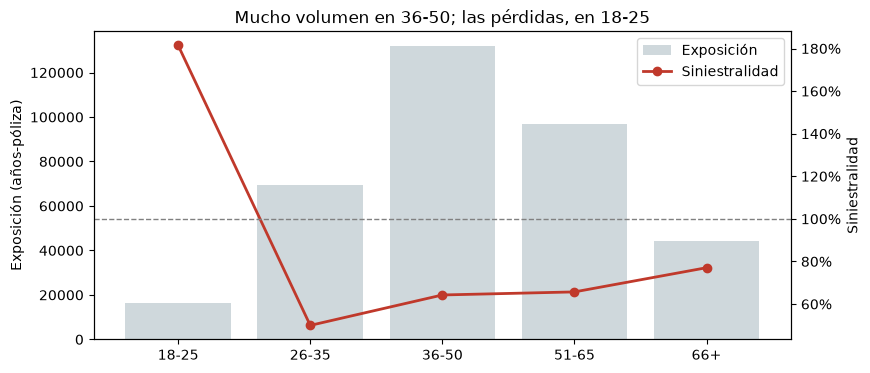

In [32]:
fig, ax1 = plt.subplots(figsize=(9, 4))
x = por_edad.index.astype(str)
ax1.bar(x, por_edad["exposicion"], color="#cfd8dc", label="Exposición")
ax1.set_ylabel("Exposición (años-póliza)")
ax2 = ax1.twinx()                          # segundo eje Y
ax2.plot(x, por_edad["siniestralidad"], color="#c0392b", marker="o", lw=2, label="Siniestralidad")
ax2.axhline(1, color="grey", ls="--", lw=1)
ax2.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax2.set_ylabel("Siniestralidad")
ax1.set_title("Mucho volumen en 36-50; las pérdidas, en 18-25")
fig.legend(loc="upper right", bbox_to_anchor=(0.9, 0.88))
plt.show()

> 💡 **El título cuenta la conclusión**, no describe el gráfico. "Siniestralidad por edad" describe; "Las pérdidas se concentran en 18–25" informa.

### Cascada (waterfall): de las primas al margen

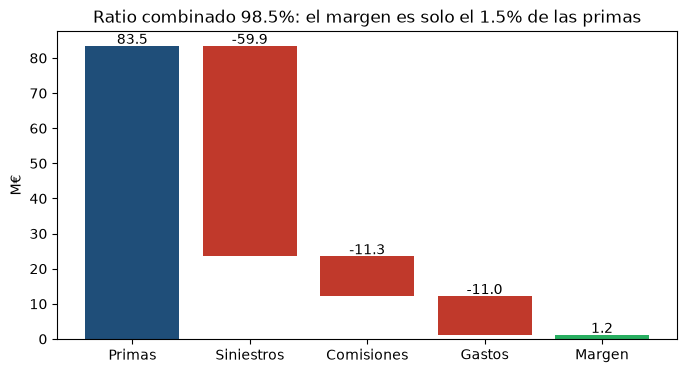

In [33]:
t = cuenta.loc["Total"]
pasos = {"Primas": t["primas"], "Siniestros": -t["siniestros"], "Comisiones": -t["comisiones"],
         "Gastos": -t["gastos"]}
acumulado = np.cumsum([0] + list(pasos.values())[:-1])
fig, ax = plt.subplots(figsize=(8, 4))
colores = ["#1f4e79"] + ["#c0392b"] * 3
ax.bar(list(pasos), [abs(v) / 1e6 for v in pasos.values()],
       bottom=[(a + min(v, 0)) / 1e6 for a, v in zip(acumulado, pasos.values())], color=colores)
ax.bar("Margen", t["margen"] / 1e6, color="#27ae60" if t["margen"] > 0 else "#c0392b")
for i, v in enumerate(list(pasos.values()) + [t["margen"]]):
    ax.text(i, (acumulado[i] if i < len(acumulado) else 0) / 1e6 + max(v, 0) / 1e6 + 0.5,
            f"{v / 1e6:,.1f}", ha="center")
ax.set_ylabel("M€")
ax.set_title(f"Ratio combinado {t['ratio_combinado']:.1%}: el margen es solo el {t['margen'] / t['primas']:.1%} de las primas")
plt.show()

### seaborn: mapa de calor en 2 líneas

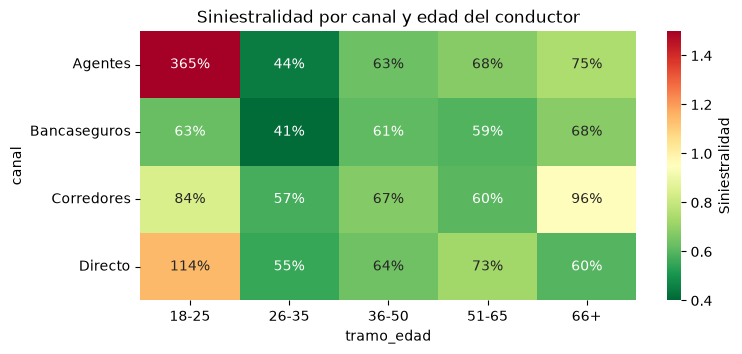

In [34]:
plt.figure(figsize=(8, 3.5))
sns.heatmap(siniestralidad_canal_edad, annot=True, fmt=".0%", cmap="RdYlGn_r", vmin=0.4, vmax=1.5,
            cbar_kws={"label": "Siniestralidad"})
plt.title("Siniestralidad por canal y edad del conductor")
plt.show()

### plotly: treemap interactivo
El tamaño de cada rectángulo es la prima y el color, la siniestralidad. Pasa el ratón por encima y haz clic para entrar en un canal.

In [35]:
import plotly.express as px

arbol = df.groupby(["canal", "region"], as_index=False).agg(primas=("prima_devengada", "sum"),
                                                             siniestros=("coste_siniestros", "sum"),
                                                             margen=("margen", "sum"))
arbol["siniestralidad"] = arbol["siniestros"] / arbol["primas"]
fig = px.treemap(arbol, path=[px.Constant("Total"), "canal", "region"], values="primas",
                 color="siniestralidad", color_continuous_scale="RdYlGn_r", range_color=(0.4, 1.2),
                 hover_data={"margen": ":,.0f"}, title="Primas (tamaño) y siniestralidad (color)")
fig.update_layout(height=550, margin=dict(t=50, l=10, r=10, b=10))
fig.show()

Un gráfico de plotly se puede guardar como **HTML autónomo**. Se envía por correo y se abre en cualquier navegador sin Python:

In [36]:
(OUTPUT / "graficos").mkdir(parents=True, exist_ok=True)
fig.write_html(OUTPUT / "graficos" / "treemap_siniestralidad.html")
print("Guardado en output/graficos/treemap_siniestralidad.html")

Guardado en output/graficos/treemap_siniestralidad.html


### ✏️ Ejercicio 4.1
Haz un gráfico de barras horizontales del **margen por canal** (sin la fila Total), en rojo si es negativo y en azul si es positivo, con un título que cuente la conclusión. Guarda la figura en la variable `fig_margen`.

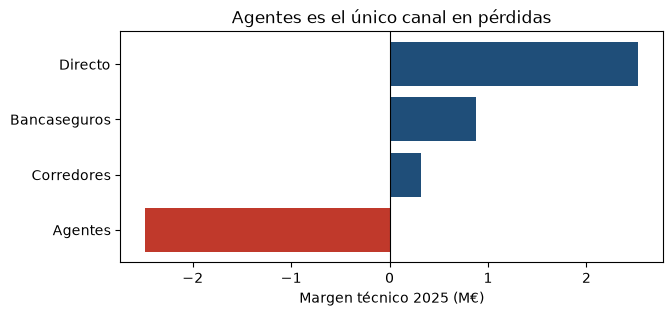

In [37]:
m = cuenta["margen"].drop("Total").sort_values()
fig_margen, ax = plt.subplots(figsize=(7, 3))
ax.barh(m.index, m / 1e6, color=np.where(m < 0, "#c0392b", "#1f4e79"))
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Margen técnico 2025 (M€)")
ax.set_title(f"{m.idxmin()} es el único canal en pérdidas")
plt.show()

In [38]:
comprobar(fig_margen is not ... and len(fig_margen.axes) >= 1, True, "Crea la figura con fig_margen, ax = plt.subplots()")

✅ ¡Correcto!


---
# ⭐ Demo: ¿y si fueran 50 millones de filas?

Excel se detiene en 1.048.576 filas. pandas trabaja en memoria y llega cómodamente a decenas de millones si el formato es eficiente. Más allá, **DuckDB** permite hacer SQL directamente sobre ficheros sin cargarlos enteros. (Todo esto se desarrolla en el notebook complementario **C1**.)

In [39]:
import duckdb

ruta = str(DATA / "cartera" / "cartera_2025.parquet")
duckdb.sql(f"""
    SELECT canal, COUNT(*) AS polizas, ROUND(SUM(prima_anual)) AS prima_anual
    FROM '{ruta}'
    GROUP BY canal ORDER BY prima_anual DESC
""").df()

,canal,polizas,prima_anual
0,Agentes,291711,"72,248,727.00"
1,Corredores,176739,"42,801,707.00"
2,Directo,143271,"36,500,155.00"
3,Bancaseguros,66270,"17,148,957.00"


---
## Resumen de la sesión
- `info`, `describe`, `value_counts` e `isna` para conocer los datos **antes** de calcular nada.
- Vectorizar (columna × columna) en vez de bucles: cientos de veces más rápido.
- `groupby().agg()` y `merge()` sustituyen a SUMAR.SI.CONJUNTO y BUSCARV.
- **Ratios = cociente de sumas.**
- Un gráfico con un título que cuenta la conclusión vale más que tres gráficos descriptivos.

**Próxima sesión:** automatizamos todo esto como proceso de cierre mensual, con ficheros sucios, controles, presupuesto, Excel, PDF y correos.